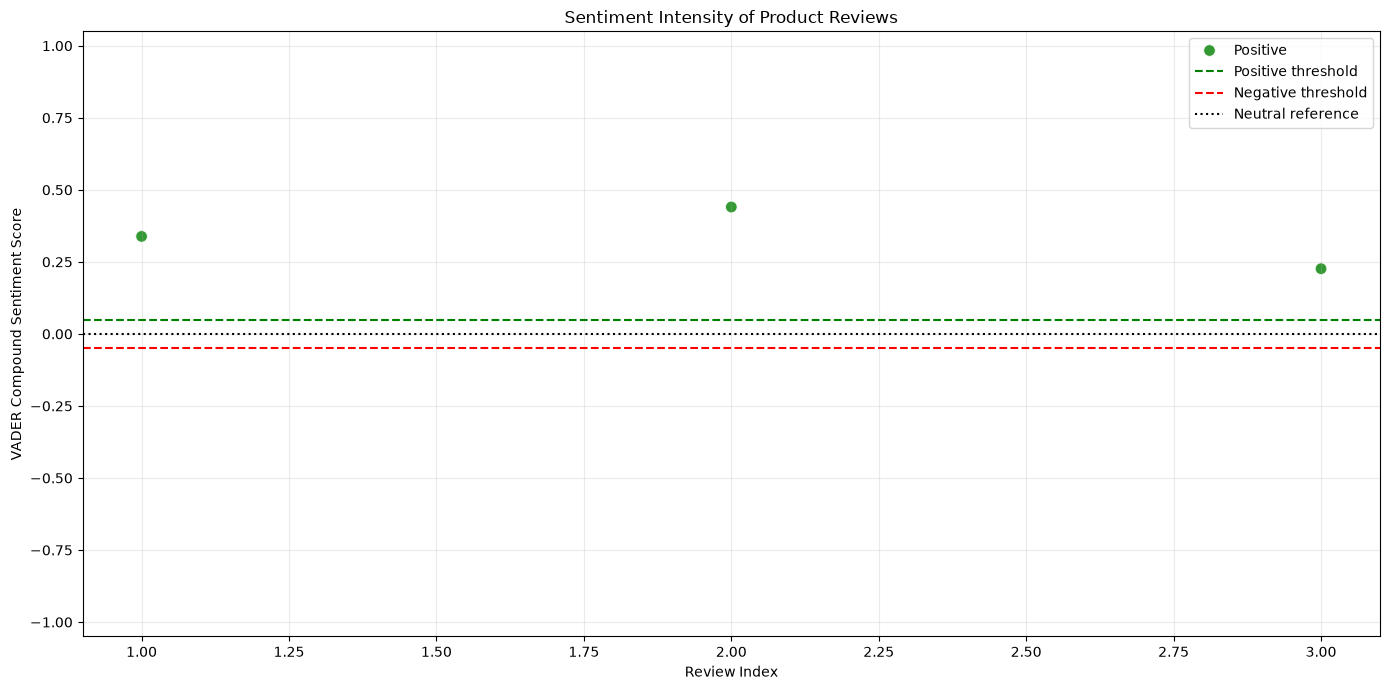

Scatter intensity plot saved successfully.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load sentiment analysis results
df = pd.read_csv("sentiment_analysis_results.csv")

# Ensure valid compound scores
df["vader_compound"] = pd.to_numeric(
    df["vader_compound"], errors="coerce"
)

df = df.dropna(subset=["vader_compound"]).reset_index(drop=True)

# Assign review indices
df["review_index"] = range(1, len(df) + 1)

# Set consistent sentiment colors
palette = {
    "Positive": "green",
    "Negative": "red",
    "Neutral": "gray"
}

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=df,
    x="review_index",
    y="vader_compound",
    hue="vader_sentiment",
    palette=palette,
    s=70,
    alpha=0.8
)

# Sentiment classification thresholds
plt.axhline(
    y=0.05, color="green", linestyle="--",
    label="Positive threshold"
)
plt.axhline(
    y=-0.05, color="red", linestyle="--",
    label="Negative threshold"
)
plt.axhline(
    y=0, color="black", linestyle=":",
    label="Neutral reference"
)

plt.ylim(-1.05, 1.05)
plt.xlabel("Review Index")
plt.ylabel("VADER Compound Sentiment Score")
plt.title("Sentiment Intensity of Product Reviews")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("sentiment_intensity_scatter.png", dpi=300)
plt.show()

print("Scatter intensity plot saved successfully.")
